# Dataset Comparison: CimaIO vs Seckin

This notebook compares the datasets of Cima et al. (CimaIO) with the datasets of Seckin et al. The two collections are analysed separately. Both contain a UAE dataset, but with different accounts, retweets and observation periods, so each UAE dataset is kept in its own collection.

**Comparison approach:**
- For each dataset: mean and std over the IO users and over the control users.
- For each collection: unweighted mean of the dataset means, with the std of the dataset means.

**Metrics:**
1. Number of retweets per user (IO vs control)
2. Number of active days per user (IO vs control): distinct calendar dates with at least one retweet

In [6]:
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from data_loader import import_data

In [7]:
def analyze_dataset(RTs, io_set):
    """Posts and active days of every IO and control user."""
    posts = {'io': Counter(), 'control': Counter()}
    days = {'io': defaultdict(set), 'control': defaultdict(set)}
    for user_id, _, ts in RTs:
        kind = 'io' if user_id in io_set else 'control'
        posts[kind][user_id] += 1
        days[kind][user_id].add(ts.date())
    return {f'{kind}_{metric}': values
            for kind in ('io', 'control')
            for metric, values in (('posts', dict(posts[kind])),
                                   ('days', {u: len(d) for u, d in days[kind].items()}))}


def compute_statistics(data_dict):
    """Count, mean, median, std and total of the values of a dict."""
    values = list(data_dict.values())
    return {"count": len(values), "mean": np.mean(values), "median": np.median(values),
            "std": np.std(values), "total": sum(values)}


def build_metric_table(collection_results, metric_key):
    """
    Per-dataset mean and std of a metric ('posts' or 'days') for IO and control users, plus an
    "Across datasets" row: mean of the dataset means and std of the dataset means.
    """
    rows = []
    for name, data in collection_results.items():
        io_stats = compute_statistics(data[f"io_{metric_key}"])
        control_stats = compute_statistics(data[f"control_{metric_key}"])
        rows.append({"Dataset": name, "IO Mean": io_stats["mean"], "IO Std": io_stats["std"],
                     "Control Mean": control_stats["mean"], "Control Std": control_stats["std"]})
    df = pd.DataFrame(rows).sort_values("Dataset").reset_index(drop=True)
    summary = pd.DataFrame([{"Dataset": "Across datasets",
                             "IO Mean": df["IO Mean"].mean(), "IO Std": df["IO Mean"].std(ddof=0),
                             "Control Mean": df["Control Mean"].mean(),
                             "Control Std": df["Control Mean"].std(ddof=0)}])
    return pd.concat([df, summary], ignore_index=True)

## Load Datasets

In [8]:
CIMA_DIR = '../datasets/CimaIO/RTs'
CIMA_DATASETS = ['Honduras', 'UAE']
SECKIN_DATASETS = [
    'Armenia', 'Bangladesh', 'Catalonia', 'China_1', 'China_2', 'Cuba',
    'Ecuador', 'Egypt_UAE', 'Ghana_Nigeria', 'Iran_1', 'Iran_2', 'Iran_3',
    'Iran_4', 'Iran_5', 'Iran_6', 'Qatar', 'Russia_1', 'Russia_2', 'Russia_3',
    'Russia_4', 'Russia_5', 'Spain', 'Thailand', 'UAE', 'Venezuela_1', 'Venezuela_2'
]
COLLECTIONS = {
    'cima': ('CimaIO', [(name, f'{CIMA_DIR}/{name}/Processed') for name in CIMA_DATASETS]),
    'seckin': ('Seckin', [(name, f'../data/{name}/Processed') for name in SECKIN_DATASETS]),
}

In [9]:
# Results and observation period (first and last retweet date) of every dataset, per collection
results = {key: {} for key in COLLECTIONS}
periods = {key: {} for key in COLLECTIONS}
for key, (label, datasets) in COLLECTIONS.items():
    for name, path in datasets:
        RTs, io_users = import_data(path)
        io_set = set(io_users)
        first, last = min(ts for _, _, ts in RTs).date(), max(ts for _, _, ts in RTs).date()
        periods[key][name] = (first, last)
        print(f"{name} ({label}): {len(RTs):,} retweets, {len(io_set):,} IO users, "
              f"{first} to {last} ({(last - first).days + 1:,} days)")
        results[key][name] = analyze_dataset(RTs, io_set)

Honduras (CimaIO): 1,023,709 retweets, 1,783 IO users, 2019-09-10 to 2020-01-08 (121 days)
UAE (CimaIO): 2,105,907 retweets, 1,829 IO users, 2019-01-26 to 2019-05-26 (121 days)
Armenia (Seckin): 35,689 retweets, 26 IO users, 2014-08-06 to 2020-11-19 (2,298 days)
Bangladesh (Seckin): 17,660 retweets, 4 IO users, 2010-07-06 to 2018-12-13 (3,083 days)
Catalonia (Seckin): 101,532 retweets, 74 IO users, 2011-11-24 to 2019-01-24 (2,619 days)
China_1 (Seckin): 1,382,458 retweets, 460 IO users, 2009-11-07 to 2019-07-25 (3,548 days)
China_2 (Seckin): 1,009,826 retweets, 166 IO users, 2009-11-07 to 2019-07-25 (3,548 days)
Cuba (Seckin): 3,968,140 retweets, 491 IO users, 2010-09-06 to 2020-07-31 (3,617 days)
Ecuador (Seckin): 1,034,452 retweets, 452 IO users, 2010-04-29 to 2019-07-30 (3,380 days)
Egypt_UAE (Seckin): 80,047 retweets, 210 IO users, 2012-01-31 to 2019-08-05 (2,744 days)
Ghana_Nigeria (Seckin): 46,614 retweets, 58 IO users, 2014-04-04 to 2020-02-29 (2,158 days)
Iran_1 (Seckin): 316,5

## Aggregated Comparison: CimaIO vs Seckin

Each table lists, per dataset, the mean and std over the IO users and over the control users. In the final row ("Across datasets"), the mean is the unweighted mean of the dataset means and the std is the std of the dataset means (not a std over users). Every dataset has the same weight, whatever its number of users.

The values of the two collections depend on how each collection was built: the observation periods differ (printed when loading), and so do the control accounts (the Seckin control accounts are active on about one day in every dataset). The IO vs control contrast within a collection is therefore more informative than a comparison of the values across collections.

In [10]:
tables = {(key, metric): build_metric_table(results[key], metric)
          for key in COLLECTIONS for metric in ('posts', 'days')}
columns = ["IO Mean", "IO Std", "Control Mean", "Control Std"]
for metric, title in (('posts', 'Retweets per user'), ('days', 'Active days per user')):
    for key, (label, _) in COLLECTIONS.items():
        print(f"{label} - {title} (IO vs Control)")
        display(tables[(key, metric)].style.format("{:.2f}", subset=columns))

CimaIO - Retweets per user (IO vs Control)


,Dataset,IO Mean,IO Std,Control Mean,Control Std
0,Honduras,47.04,116.61,4.54,16.43
1,UAE,84.97,152.47,5.24,32.74
2,Across datasets,66.00,18.96,4.89,0.35


Seckin - Retweets per user (IO vs Control)


,Dataset,IO Mean,IO Std,Control Mean,Control Std
0,Armenia,20.08,13.14,26.46,43.36
1,Bangladesh,255.00,329.93,26.20,50.12
2,Catalonia,82.38,232.34,38.78,52.09
3,China_1,774.03,9389.49,30.72,39.93
4,China_2,4042.59,42443.48,16.80,25.73
5,Cuba,6804.81,15842.61,27.19,40.93
6,Ecuador,1278.21,2320.03,26.22,46.54
7,Egypt_UAE,342.30,1565.81,29.80,32.20
8,Ghana_Nigeria,281.21,836.99,30.64,32.29
9,Iran_1,397.84,933.06,23.86,30.15


CimaIO - Active days per user (IO vs Control)


,Dataset,IO Mean,IO Std,Control Mean,Control Std
0,Honduras,18.58,16.00,3.14,6.19
1,UAE,18.57,16.29,3.48,7.61
2,Across datasets,18.58,0.00,3.31,0.17


Seckin - Active days per user (IO vs Control)


,Dataset,IO Mean,IO Std,Control Mean,Control Std
0,Armenia,3.12,2.24,1.06,0.51
1,Bangladesh,71.50,73.70,1.03,0.39
2,Catalonia,39.00,76.57,1.11,0.48
3,China_1,35.45,111.30,1.04,0.27
4,China_2,102.16,263.84,1.02,0.17
5,Cuba,142.43,189.76,1.10,0.81
6,Ecuador,77.11,179.26,1.06,0.51
7,Egypt_UAE,33.86,80.72,1.00,0.06
8,Ghana_Nigeria,40.26,63.80,1.01,0.11
9,Iran_1,75.40,106.49,1.01,0.13


## Visualizations

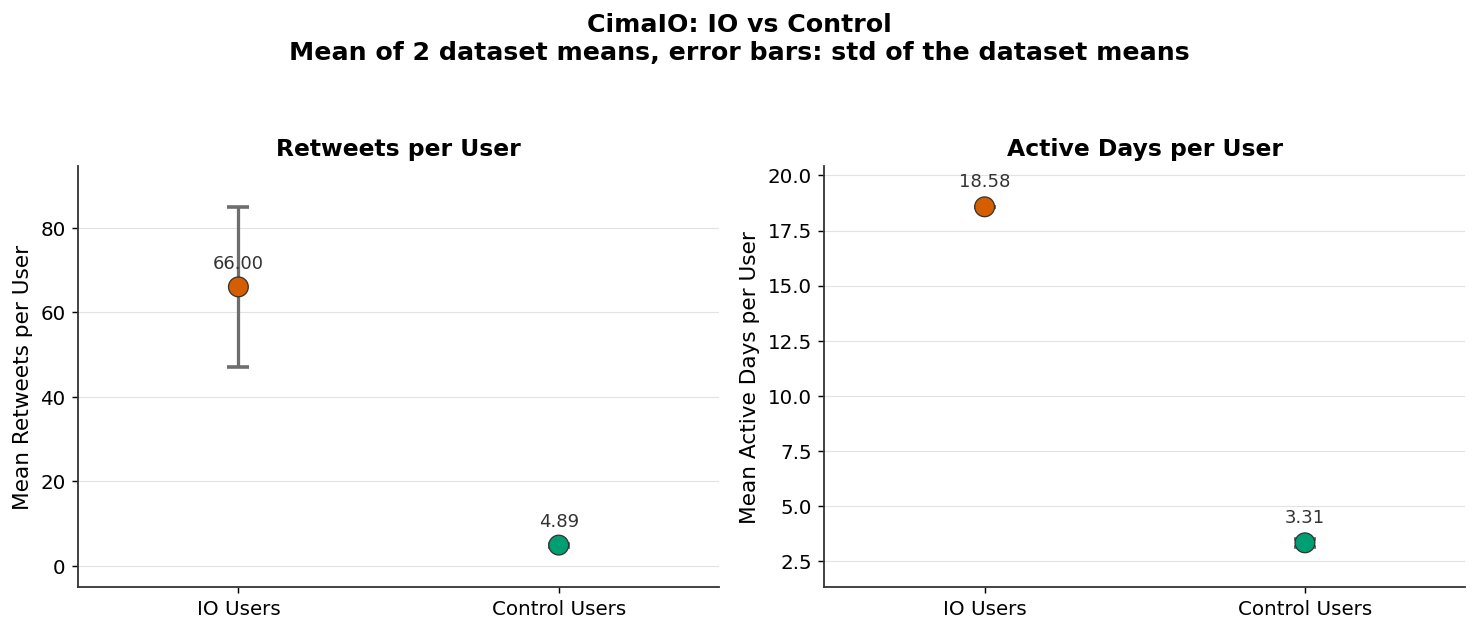

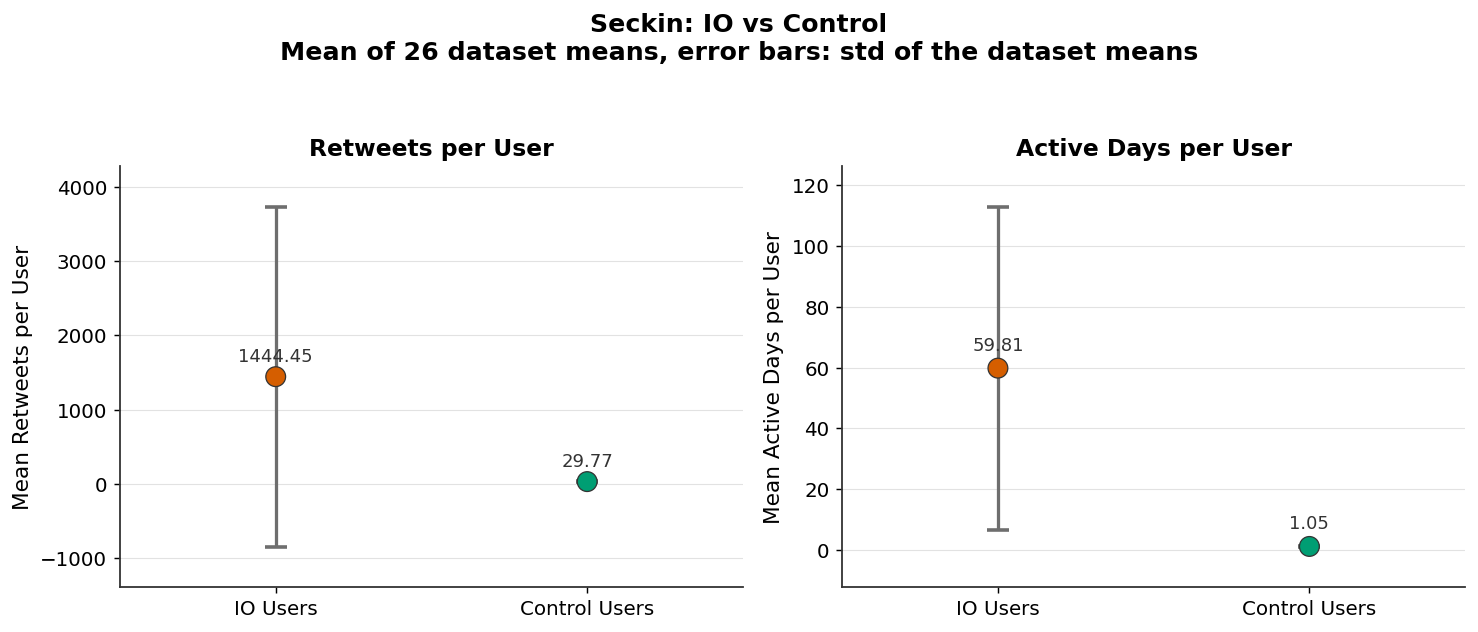

In [6]:
# Comparison figure: two panels per collection (retweets and active days); means and stds of the dataset means
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 1.0,
    "grid.color": "#d0d0d0",
    "grid.linestyle": "-",
    "grid.linewidth": 0.6,
})


def summary_from_table(table):
    """(IO mean, IO std, control mean, control std) of the "Across datasets" row."""
    summary = table[table["Dataset"] == "Across datasets"].iloc[0]
    return tuple(float(summary[c]) for c in ("IO Mean", "IO Std", "Control Mean", "Control Std"))


def plot_panel(ax, metric_title, io_mean, io_std, control_mean, control_std, ylabel):
    x = np.array([0, 1])
    means = np.array([io_mean, control_mean])
    stds = np.array([io_std, control_std])
    colors = ["#d55e00", "#009e73"]  # colorblind-friendly palette

    ax.errorbar(x, means, yerr=stds, fmt="+", markersize=10, markeredgewidth=2.0, capsize=6, elinewidth=1.8,
                color="#333333", ecolor="#6e6e6e", zorder=2)
    ax.scatter(x, means, s=120, c=colors, edgecolor="#333333", linewidth=0.7, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(["IO Users", "Control Users"])
    ax.set_ylabel(ylabel)
    ax.set_title(metric_title, fontweight="semibold")
    ax.grid(axis="y", alpha=0.6, zorder=0)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    y_max = (means + stds).max()
    y_offset = 0.04 * y_max if y_max else 0.1
    for xi, mean_val in zip(x, means):
        ax.text(xi, mean_val + y_offset, f"{mean_val:.2f}", ha="center", va="bottom", fontsize=10, color="#333333")
    ax.set_xlim(-0.5, 1.5)
    ax.margins(y=0.12)


def plot_collection_figure(label, n_datasets, retweets_stats, days_stats):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=False)
    fig.suptitle(f"{label}: IO vs Control\nMean of {n_datasets} dataset means, error bars: std of the dataset means",
                 fontsize=14, fontweight="semibold", y=1.05)
    plot_panel(axes[0], "Retweets per User", *retweets_stats, "Mean Retweets per User")
    plot_panel(axes[1], "Active Days per User", *days_stats, "Mean Active Days per User")
    plt.tight_layout()
    plt.show()


for key, (label, _) in COLLECTIONS.items():
    plot_collection_figure(label, len(results[key]), summary_from_table(tables[(key, 'posts')]),
                           summary_from_table(tables[(key, 'days')]))

In [7]:
# Detailed statistics of every dataset, keyed by (collection, dataset): both collections have a UAE dataset
for key, name in sorted(((key, name) for key in COLLECTIONS for name in results[key]), key=lambda kn: kn[::-1]):
    label = COLLECTIONS[key][0]
    stats = {k: compute_statistics(v) for k, v in results[key][name].items()}
    first, last = periods[key][name]

    print(f"\n{'='*60}")
    print(f"{name.upper()} ({label})")
    print(f"{'='*60}")
    print(f"\n{label} Dataset, {first} to {last} ({(last - first).days + 1:,} days):")
    print(f"  Retweets/user - IO:      {stats['io_posts']['mean']:>6.2f} ± {stats['io_posts']['std']:>6.2f} "
          f"({stats['io_posts']['count']:>6,} users)")
    print(f"  Retweets/user - Control: {stats['control_posts']['mean']:>6.2f} ± {stats['control_posts']['std']:>6.2f} "
          f"({stats['control_posts']['count']:>6,} users)")
    print(f"  Days/user     - IO:      {stats['io_days']['mean']:>6.2f} ± {stats['io_days']['std']:>6.2f}")
    print(f"  Days/user     - Control: {stats['control_days']['mean']:>6.2f} ± {stats['control_days']['std']:>6.2f}")


ARMENIA (Seckin)

Seckin Dataset, 2014-08-06 to 2020-11-19 (2,298 days):
  Retweets/user - IO:       20.08 ±  13.14 (    26 users)
  Retweets/user - Control:  26.46 ±  43.36 ( 1,329 users)
  Days/user     - IO:        3.12 ±   2.24
  Days/user     - Control:   1.06 ±   0.51

BANGLADESH (Seckin)

Seckin Dataset, 2010-07-06 to 2018-12-13 (3,083 days):
  Retweets/user - IO:      255.00 ± 329.93 (     4 users)
  Retweets/user - Control:  26.20 ±  50.12 (   635 users)
  Days/user     - IO:       71.50 ±  73.70
  Days/user     - Control:   1.03 ±   0.39

CATALONIA (Seckin)

Seckin Dataset, 2011-11-24 to 2019-01-24 (2,619 days):
  Retweets/user - IO:       82.38 ± 232.34 (    74 users)
  Retweets/user - Control:  38.78 ±  52.09 ( 2,461 users)
  Days/user     - IO:       39.00 ±  76.57
  Days/user     - Control:   1.11 ±   0.48

CHINA_1 (Seckin)

Seckin Dataset, 2009-11-07 to 2019-07-25 (3,548 days):
  Retweets/user - IO:      774.03 ± 9389.49 (   460 users)
  Retweets/user - Control:  30.72 

## Cima datasets comparing IO vs Control in weighted co-retweet approaches

Co-retweets: retweets of the same tweet by two users within $\Delta t = 60$ s. Scenario S1 keeps every pair with at least one co-retweet and S2 the pairs with at least two. For the co-retweets of the kept pairs, split into pairs with at least one IO account and pairs of two control accounts:
- median $m(\iota)$: number of retweets of the retweeted tweet,
- median $w_T$: weight of the co-retweet with $T = 12$h, $(m_{T_k}(\iota) + m_{T_{k'}}(\iota)) / (2\,m(\iota))$.

The medians are taken over co-retweets, so a tweet counts once for each of its co-retweets.

In [8]:
from analysis import graph_jackknife as gj

WINDOW_SEC = 60
SCENARIOS = [('S1', 1), ('S2', 2)]


def coretweet_popularity_and_weight(g, min_coactions):
    """Median m(tweet) and median w_T of the co-retweets of the pairs with and without an IO account."""
    cohort = gj.FixedCohort(g, min_coactions)
    k, c = gj.unit_multiplicities(g)
    q = gj.primed_quantities(g, k, c)
    units = cohort.units
    m = q['m'][g.unit_tweet[units]]
    w = (q['m_T'][g.unit_tp1[units]] + q['m_T'][g.unit_tp2[units]]) / (2.0 * m)
    pair = g.unit_pair[units]
    with_io = g.io[g.pair_u[pair]] | g.io[g.pair_v[pair]]
    return {'m IO': np.median(m[with_io]), 'm Control': np.median(m[~with_io]),
            'w_T IO': np.median(w[with_io]), 'w_T Control': np.median(w[~with_io])}


rows = []
for name, path in COLLECTIONS['cima'][1]:
    RTs, io_users = import_data(path)
    g = gj.SyncGraph(RTs, io_users, WINDOW_SEC)
    del RTs
    for scenario, min_coactions in SCENARIOS:
        rows.append({'Scenario': scenario, 'Dataset': name, **coretweet_popularity_and_weight(g, min_coactions)})
    del g
weighted_table = pd.DataFrame(rows).sort_values(['Scenario', 'Dataset']).reset_index(drop=True)
display(weighted_table.style.format({'m IO': '{:,.0f}', 'm Control': '{:,.0f}',
                                     'w_T IO': '{:.2f}', 'w_T Control': '{:.2f}'}))

,Scenario,Dataset,m IO,m Control,w_T IO,w_T Control
0,S1,Honduras,236,"1,514",0.97,0.65
1,S1,UAE,149,"1,393",0.81,0.58
2,S2,Honduras,235,313,0.98,0.70
3,S2,UAE,97,81,0.86,0.73


## Cima datasets: pairs with a single co-retweet, IO vs Control

Co-retweet count $c(u,v)$ of a pair of users: number of distinct tweets that $u$ and $v$ both retweeted within $\Delta t = 60$ s of each other. Every pair with $c(u,v) \geq 1$ is kept (scenario S1), and the users are those with at least one such pair. Pairs are split into pairs with at least one IO account (IO) and pairs of two control accounts (Control), and users into IO and control accounts:
- Pairs with $c=1$ (%): percentage of the pairs with $c(u,v) = 1$.
- Users with only $c=1$ (%): percentage of the users all of whose pairs have $c(u,v) = 1$.
- Median partners: median over the users of their number of partners, the users $v$ with $c(u,v) \geq 1$.

In [9]:
from analysis.descriptives import coretweet_pair_statistics

WINDOW_SEC = 60
SCENARIOS = [('S1', 1), ('S2', 2)]

ties = coretweet_pair_statistics([(CIMA_DIR, name, WINDOW_SEC) for name in CIMA_DATASETS])
ties_table = pd.DataFrame({
    'Dataset': ties['dataset'],
    'Pairs with c=1, IO (%)': 100 * ties['c1_share_io'],
    'Pairs with c=1, Control (%)': 100 * ties['c1_share_control'],
    'Users with only c=1, IO (%)': 100 * ties['single_io_share'],
    'Users with only c=1, Control (%)': 100 * ties['single_control_share'],
    'Median partners, IO': ties['ties_io_median'],
    'Median partners, Control': ties['ties_control_median'],
}).sort_values('Dataset').reset_index(drop=True)
display(ties_table.style.format({column: '{:.1f}' if column.endswith('(%)') else '{:g}'
                                 for column in ties_table.columns if column != 'Dataset'}))

Ties: Honduras (window 60 s)


Ties: UAE (window 60 s)


,Dataset,"Pairs with c=1, IO (%)","Pairs with c=1, Control (%)","Users with only c=1, IO (%)","Users with only c=1, Control (%)","Median partners, IO","Median partners, Control"
0,Honduras,31.5,99.1,5.5,95.1,120,4
1,UAE,64.6,99.2,21.3,96.5,14,4
